# AI-Powered Traffic Congestion Classification
### CNN Transfer Learning + Fine-Tuning + Interactive Interface

**Goal:** classify traffic images into Low, Moderate, or High congestion using a CNN-based model (MobileNetV2) with transfer learning, then let users upload an image and see the model's prediction in a Gradio interface.


```

## 1. Install libraries
Run the cells in order. Colab's GPU runtime can speed up training: **Runtime → Change runtime type → T4 GPU** if available.

In [20]:
!pip install -q gradio scikit-learn matplotlib

## 2. Import libraries and set reproducibility

In [21]:
import os
import json
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import gradio as gr

from google.colab import files
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 3

CLASS_NAMES = ["low", "moderate", "high"]

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Project setup completed.")

TensorFlow: 2.21.0
GPU devices: []
Project setup completed.


In [22]:
!rm -rf /content/traffic_dataset
!pip install -q datasets
import os, random
from datasets import load_dataset

extract_path = "/content/traffic_dataset"

random.seed(42)
ds_all = load_dataset("ilsilfverskiold/traffic-camera-norway-images")
ds = ds_all[list(ds_all.keys())[0]]
names = ds.features["label"].names
print("Original labels:", names)

mapping = {"high-traffic": "high", "medium-traffic": "moderate",
           "low-traffic": "low", "no-traffic": "low"}
MAX_PER_CLASS = 400

root = extract_path
by_class = {"low": [], "moderate": [], "high": []}
for i, lab in enumerate(ds["label"]):
    by_class[mapping[names[lab]]].append(i)

for cls, idxs in by_class.items():
    os.makedirs(f"{root}/{cls}", exist_ok=True)
    random.shuffle(idxs)
    for n, i in enumerate(idxs[:MAX_PER_CLASS]):
        ds[i]["image"].convert("RGB").save(f"{root}/{cls}/{cls}_{n}.jpg")
    print(cls, "available:", len(idxs), "| saved:", min(len(idxs), MAX_PER_CLASS))

Original labels: ['high-traffic', 'low-traffic', 'medium-traffic', 'no-traffic']
low available: 4331 | saved: 400
moderate available: 1187 | saved: 400
high available: 585 | saved: 400


## 4. Find class folders and create a train/validation split
This uses a stratified split so each class is represented in both subsets when enough images are available. For stronger academic evaluation, keep a separate test dataset that was not used for training or model selection.

In [4]:
def find_dataset_directory(base_path):
    required = set(CLASS_NAMES)

    for current_path, directories, _ in os.walk(base_path):
        # Match folder names without regard to capitalization.
        folder_map = {name.lower(): name for name in directories}

        if required.issubset(folder_map.keys()):
            return {
                class_name: os.path.join(
                    current_path, folder_map[class_name]
                )
                for class_name in CLASS_NAMES
            }

    raise FileNotFoundError(
        "Could not find low, moderate, and high folders. "
        "Check the folder structure inside your ZIP."
    )


class_dirs = find_dataset_directory(extract_path)

for class_name, folder in class_dirs.items():
    count = sum(
        1 for name in os.listdir(folder)
        if name.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    )
    print(f"{class_name}: {count} images")

    if count < 2:
        raise ValueError(
            f"The '{class_name}' folder needs at least two images."
        )

DATASET_DIR = os.path.dirname(class_dirs["low"])

# Ensure all class folders belong to the same parent directory.
if any(
    os.path.dirname(path) != DATASET_DIR
    for path in class_dirs.values()
):
    raise ValueError("The three class folders must share one parent folder.")

print("Dataset directory:", DATASET_DIR)

low: 400 images
moderate: 400 images
high: 400 images
Dataset directory: /content/traffic_dataset


## 5. Load and preprocess the images

In [5]:
train_ds = keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    class_names=CLASS_NAMES,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    class_names=CLASS_NAMES,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Class mapping:", dict(enumerate(CLASS_NAMES)))
print("Training and validation datasets are ready.")

Found 1200 files belonging to 3 classes.
Using 960 files for training.
Found 1200 files belonging to 3 classes.
Using 240 files for validation.
Class mapping: {0: 'low', 1: 'moderate', 2: 'high'}
Training and validation datasets are ready.


## 6. Display sample traffic images

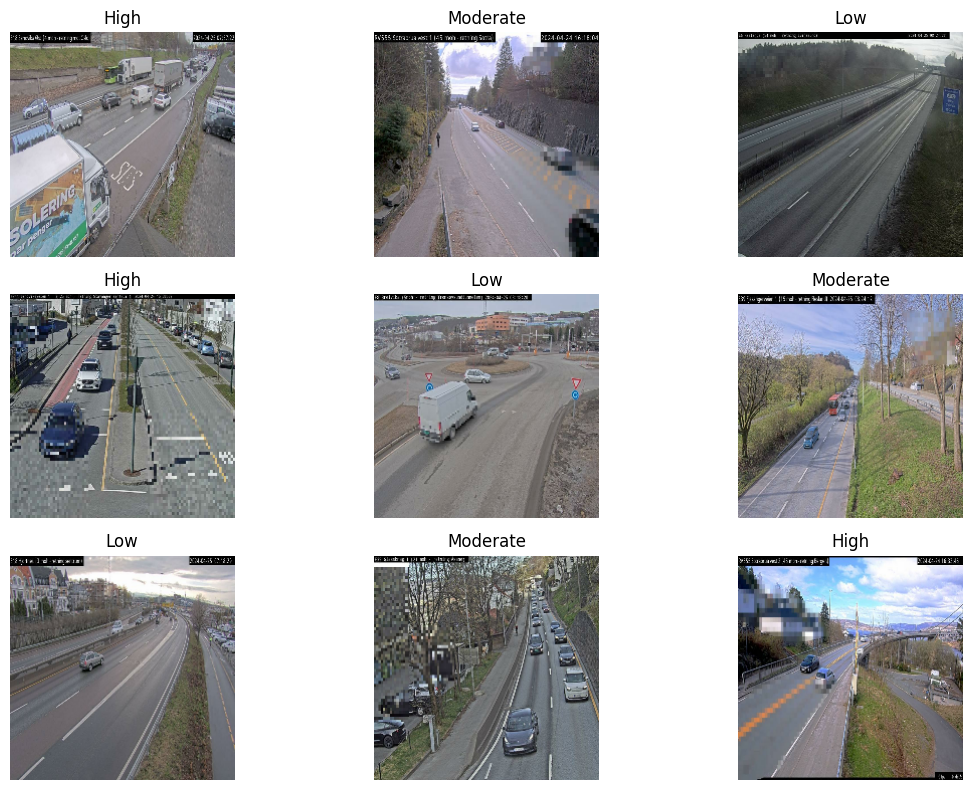

In [6]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[int(labels[i])].capitalize())
        plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Build the CNN using MobileNetV2 transfer learning
MobileNetV2 has pretrained visual features. Initially, we freeze its layers and train a new classification head for the three congestion classes.

In [7]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="data_augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# MobileNetV2 expects input pixel values scaled to [-1, 1].
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="congestion_prediction"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ congestion_prediction (Dense)   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 8. Train the classification head

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "/content/best_traffic_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_initial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 88s 3s/step - accuracy: 0.3635 - loss: 1.4055 - val_accuracy: 0.5042 - val_loss: 1.0109
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.4823 - loss: 1.0659 - val_accuracy: 0.5042 - val_loss: 0.9701
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 70s 2s/step - accuracy: 0.5562 - loss: 0.9747 - val_accuracy: 0.6542 - val_loss: 0.8287
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.6198 - loss: 0.8624 - val_accuracy: 0.5917 - val_loss: 0.8308
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 77s 3s/step - accuracy: 0.6187 - loss: 0.8363 - val_accuracy: 0.6083 - val_loss: 0.8362
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 93s 3s/step - accuracy: 0.6198 - loss: 0.8325 - val_accuracy: 0.6625 - val_loss: 0.7618
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 79s 3s/step - accuracy: 0.6354 - loss: 0.8081 - val_accuracy: 0.5958 - val_loss: 0.8629
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.6479 - loss: 0.7884 - val_accuracy: 0.6417 - val_loss:

## 9. Fine-tune the pretrained CNN
This step unfreezes the later MobileNetV2 layers so the network can adapt its pretrained features to traffic congestion images.

In [9]:
base_model.trainable = True

# Freeze earlier layers and fine-tune only the later layers.
fine_tune_from = max(0, len(base_model.layers) - 30)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for more stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 93s 3s/step - accuracy: 0.6719 - loss: 0.7703 - val_accuracy: 0.6417 - val_loss: 0.7653
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 135s 3s/step - accuracy: 0.6802 - loss: 0.7400 - val_accuracy: 0.6458 - val_loss: 0.7682
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 91s 3s/step - accuracy: 0.6740 - loss: 0.7256 - val_accuracy: 0.6500 - val_loss: 0.7489
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 90s 3s/step - accuracy: 0.6896 - loss: 0.6923 - val_accuracy: 0.6708 - val_loss: 0.6972
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 89s 3s/step - accuracy: 0.7229 - loss: 0.6533 - val_accuracy: 0.6750 - val_loss: 0.7034
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 83s 3s/step - accuracy: 0.7323 - loss: 0.6173 - val_accuracy: 0.6875 - val_loss: 0.6983
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 148s 3s/step - accuracy: 0.7292 - loss: 0.6195 - val_accuracy: 0.7375 - val_loss: 0.6632
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.7115 - loss: 0.6308 - val_accuracy: 0.7125 - val_los

## 10. Plot training and validation accuracy

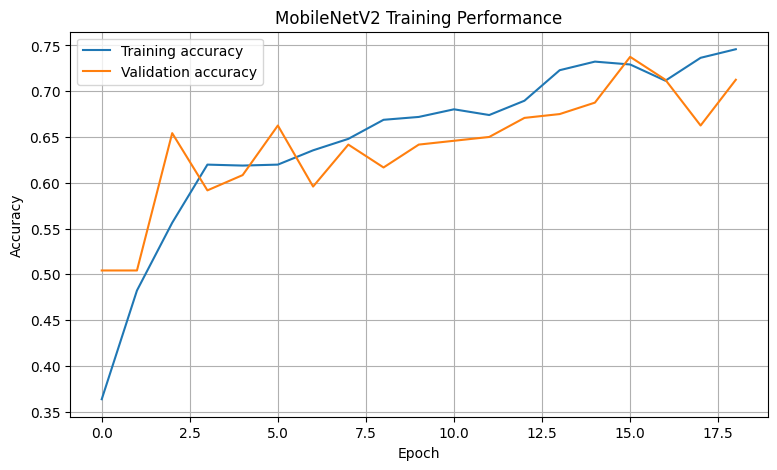

In [10]:
train_accuracy = (
    history_initial.history["accuracy"]
    + history_finetune.history["accuracy"]
)

val_accuracy = (
    history_initial.history["val_accuracy"]
    + history_finetune.history["val_accuracy"]
)

plt.figure(figsize=(9, 5))
plt.plot(train_accuracy, label="Training accuracy")
plt.plot(val_accuracy, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Training Performance")
plt.legend()
plt.grid(True)
plt.show()

## 11. Evaluate the model

8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.7125 - loss: 0.6478
Validation loss: 0.6478
Validation accuracy: 0.7125
Validation accuracy percentage: 71.25%

Classification Report:
              precision    recall  f1-score   support

         Low       0.73      0.82      0.77        71
    Moderate       0.73      0.43      0.54        82
        High       0.69      0.90      0.78        87

    accuracy                           0.71       240
   macro avg       0.72      0.71      0.70       240
weighted avg       0.72      0.71      0.70       240



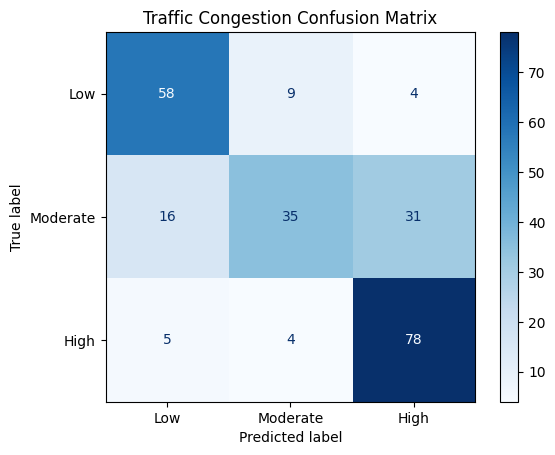

In [11]:
loss, accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation loss: {loss:.4f}")
print(f"Validation accuracy: {accuracy:.4f}")
print(f"Validation accuracy percentage: {accuracy * 100:.2f}%")

y_true = []
y_pred = []

for images, labels in val_ds:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=["Low", "Moderate", "High"],
        zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Moderate", "High"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Traffic Congestion Confusion Matrix")
plt.show()

## 12. Save the trained model

In [12]:
MODEL_PATH = "/content/traffic_congestion_mobilenetv2.keras"
CLASS_PATH = "/content/class_names.json"

model.save(MODEL_PATH)

with open(CLASS_PATH, "w") as f:
    json.dump(CLASS_NAMES, f)

print("Model saved:", MODEL_PATH)
print("Class names saved:", CLASS_PATH)

Model saved: /content/traffic_congestion_mobilenetv2.keras
Class names saved: /content/class_names.json


## 13. Test the model on a single image

In [13]:
from PIL import Image

def predict_traffic(image):
    if image is None:
        return {"Please upload an image": 1.0}

    image = image.convert("RGB").resize(IMG_SIZE)
    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]

    return {
        CLASS_NAMES[i].capitalize(): float(probabilities[i])
        for i in range(NUM_CLASSES)
    }

print("Prediction function is ready.")

Prediction function is ready.


## 14. Create the interactive Gradio interface
Upload a road image, submit it, and the interface will display the predicted congestion class with confidence scores.

In [ ]:
demo = gr.Interface(
    fn=predict_traffic,
    inputs=gr.Image(
        type="pil",
        label="Upload a traffic or road image"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="Predicted congestion level"
    ),
    title="AI-Powered Traffic Congestion Classification",
    description=(
        "A CNN transfer-learning project using MobileNetV2 "
        "to classify traffic images as Low, Moderate, or High congestion."
    ),
    examples=None
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://9cb4121184910789af.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14.Download the trained model
Run this cell after training if you want to save the model to your computer.

In [15]:
from google.colab import files

files.download("/content/traffic_congestion_mobilenetv2.keras")
files.download("/content/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
%%writefile app.py
import os
import json
import numpy as np
import tensorflow as tf
import gradio as gr

MODEL_PATH = "traffic_congestion_mobilenetv2.keras"
CLASS_NAMES_PATH = "/app/class_names.json"

model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_NAMES_PATH, "r") as f:
    class_names = json.load(f)

def predict_traffic(image):
    if image is None:
        return {}

    image = image.convert("RGB").resize((224, 224))
    image_array = np.array(image, dtype=np.float32)

    # Use the same preprocessing as your original Colab model.
    image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
        image_array
    )

    image_array = np.expand_dims(image_array, axis=0)
    predictions = model.predict(image_array, verbose=0)[0]

    return {
        str(class_names[i]): float(predictions[i])
        for i in range(len(class_names))
    }

demo = gr.Interface(
    fn=predict_traffic,
    inputs=gr.Image(type="pil", label="Upload a traffic or road image"),
    outputs=gr.Label(num_top_classes=3, label="Predicted congestion level"),
    title="AI-Powered Traffic Congestion Classification",
    description=(
        "A CNN transfer-learning project using MobileNetV2 "
        "to classify traffic images as Low, Moderate, or High congestion."
    )
)

port = int(os.environ.get("PORT", "8080"))
demo.launch(server_name="0.0.0.0", server_port=port)

Overwriting app.py


In [17]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>